# Random Forest Models

**Research Question 3**: What factors affect a restaurant's food safety performance and inspection score?

This notebook builds two Random Forest models using the same predictor definitions and train/test split as the logistic regression and decision-tree work:
1. **Classification**: predict whether an inspection score is 14 or higher (SCORE_14PLUS).
2. **Regression**: predict LOG_SCORE = log(1 + SCORE).

We use the same 70/30 stratified split (random_state=42) so model comparisons are more meaningful. Random Forests do not require numeric predictors to be standardized, so we use the median-imputed predictors without z-score scaling.

**Important interpretation**: This is inspection-level prediction, not a causal analysis. Feature importance tells us which predictors the model uses most—not that those predictors cause food-safety outcomes.

## Data Preparation
--- 

In [27]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report,
    mean_squared_error, mean_absolute_error, r2_score
)

RANDOM_STATE = 42

In [28]:
# Read the inspection-level prepared dataset; preserve ZIP/BBL codes as strings and parse inspection dates.
df = pd.read_csv(
    "data/inspection_level_plus.csv",
    dtype={"ZIPCODE": "string", "BBL": "string", "ZIP5": "string"},
    parse_dates=["INSPECTION DATE"],
    low_memory=False
)

# Transform the numeric inspection score to log(1 + score) for the regression target.
df["LOG_SCORE"] = np.log1p(df["SCORE"])

# Create the binary outcome: 1 for scores of 14 or more; 0 for scores below 14.
# Leave missing scores as NaN rather than treating them as a class.
df["SCORE_14PLUS"] = np.where(
    df["SCORE"].notna(), (df["SCORE"] >= 14).astype(int), np.nan
)


# Check dataset dimensions, available variables, and score distribution.
print("Dataset shape:", df.shape)
print("Columns:", list(df.columns))
print("Score Distribution (Target):\n", df["SCORE"].describe())

Dataset shape: (93292, 58)
Columns: ['REPRESENTATIVE_SOURCE_ROW_ID', 'CAMIS', 'DBA', 'BORO', 'BUILDING', 'STREET', 'ZIPCODE', 'PHONE', 'CUISINE DESCRIPTION', 'INSPECTION DATE', 'ACTION', 'SCORE', 'GRADE', 'GRADE DATE', 'RECORD DATE', 'INSPECTION TYPE', 'Latitude', 'Longitude', 'Community Board', 'Council District', 'Census Tract', 'BIN', 'BBL', 'NTA', 'Location', 'AWAITING_INSPECTION', 'BORO_UNKNOWN', 'ZERO_COORDINATES', 'BBL_INCOMPLETE', 'GRADE_CATEGORY', '_has_violation_code', '_is_critical_violation', '_is_non_critical_violation', 'violation_record_count', 'total_violation_count', 'missing_violation_code_row_count', 'critical_violation_count', 'non_critical_violation_count', 'not_applicable_flag_record_count', 'unique_violation_code_count', 'violation_description_record_count', 'score_band', 'critical_violation_pct', 'bldgclass', 'landuse', 'lotarea', 'bldgarea', 'numfloors', 'unitsres', 'unitstotal', 'assesstot', 'yearbuilt', 'pluto_matched', 'ZIP5', 'median_hh_income', 'population

In [29]:
df

,REPRESENTATIVE_SOURCE_ROW_ID,CAMIS,DBA,BORO,BUILDING,STREET,ZIPCODE,PHONE,CUISINE DESCRIPTION,INSPECTION DATE,...,unitsres,unitstotal,assesstot,yearbuilt,pluto_matched,ZIP5,median_hh_income,population,LOG_SCORE,SCORE_14PLUS
0,172870,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462,7188924968,Bakery Products/Desserts,2023-08-01,...,1.0,2.0,81360.0,1957.0,1,10462,60966.0,76320.0,3.663562,1.0
1,210601,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462,7188924968,Bakery Products/Desserts,2023-08-22,...,1.0,2.0,81360.0,1957.0,1,10462,60966.0,76320.0,2.564949,0.0
2,9888,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462,7188924968,Bakery Products/Desserts,2024-11-08,...,1.0,2.0,81360.0,1957.0,1,10462,60966.0,76320.0,2.397895,0.0
3,147982,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462,7188924968,Bakery Products/Desserts,2026-02-27,...,1.0,2.0,81360.0,1957.0,1,10462,60966.0,76320.0,2.079442,0.0
4,45216,30191841,D.J. REYNOLDS,Manhattan,351,WEST 57 STREET,10019,2122452912,Irish,2024-11-20,...,8.0,9.0,1942650.0,1930.0,1,10019,128559.0,44942.0,3.218876,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93287,43082,50190758,LA CHAPINCITA,Brooklyn,1806,BATH AVENUE,11214,9176768543,Mexican,2026-08-17,...,1.0,2.0,50280.0,1920.0,1,11214,65895.0,89397.0,4.543295,1.0
93288,108162,50190758,LA CHAPINCITA,Brooklyn,1806,BATH AVENUE,11214,9176768543,Mexican,2026-08-24,...,1.0,2.0,50280.0,1920.0,1,11214,65895.0,89397.0,NaN,NaN
93289,67488,50190758,LA CHAPINCITA,Brooklyn,1806,BATH AVENUE,11214,9176768543,Mexican,2026-08-24,...,1.0,2.0,50280.0,1920.0,1,11214,65895.0,89397.0,3.737670,1.0
93290,49178,50190766,GUACODA RESTAURANT,Queens,157-02,CROSSBAY BOULEVARD,11414,__________,Other,2026-08-14,...,0.0,9.0,2142450.0,1989.0,1,11414,95051.0,31308.0,4.382027,1.0


In [30]:
df.describe(include='all')

,REPRESENTATIVE_SOURCE_ROW_ID,CAMIS,DBA,BORO,BUILDING,STREET,ZIPCODE,PHONE,CUISINE DESCRIPTION,INSPECTION DATE,...,unitsres,unitstotal,assesstot,yearbuilt,pluto_matched,ZIP5,median_hh_income,population,LOG_SCORE,SCORE_14PLUS
count,93292.000000,9.329200e+04,93292,93292,92879,93291,92267,93280,93292,93292,...,90461.000000,90461.000000,9.046100e+04,89978.000000,93292.000000,92267,91088.000000,91868.000000,82956.000000,82956.000000
unique,NaN,NaN,21606,6,8225,2155,238,25231,91,NaN,...,NaN,NaN,NaN,NaN,NaN,238,NaN,NaN,NaN,NaN
top,NaN,NaN,DUNKIN,Manhattan,1,BROADWAY,10003,7185958100,American,NaN,...,NaN,NaN,NaN,NaN,NaN,10003,NaN,NaN,NaN,NaN
freq,NaN,NaN,1382,35549,548,3645,2145,103,15033,NaN,...,NaN,NaN,NaN,NaN,NaN,2145,NaN,NaN,NaN,NaN
mean,88286.690681,4.810415e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024-11-19 14:46:09.729451264,...,30.265374,40.262942,3.304977e+07,1935.267621,0.969783,NaN,103999.831734,53903.529172,2.656265,0.401249
min,2.000000,3.007544e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2007-08-10 00:00:00,...,0.000000,0.000000,0.000000e+00,1719.000000,0.000000,NaN,24086.000000,0.000000,0.000000,0.000000
25%,28202.750000,5.000598e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024-02-20 00:00:00,...,0.000000,3.000000,4.248000e+05,1915.000000,1.000000,NaN,70027.000000,34049.000000,2.302585,0.000000
50%,67487.500000,5.009557e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-14 00:00:00,...,2.000000,6.000000,1.229850e+06,1930.000000,1.000000,NaN,93854.000000,52971.000000,2.639057,0.000000
75%,132610.250000,5.013321e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-11-20 00:00:00,...,8.000000,18.000000,4.060350e+06,1950.000000,1.000000,NaN,137106.000000,74817.000000,3.218876,1.000000
max,295987.000000,5.019077e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-08-24 00:00:00,...,8764.000000,8812.000000,8.496376e+09,2025.000000,1.000000,NaN,250001.000000,105716.000000,5.370638,1.000000


#### Create chain indicator

These features summarize information available from earlier scored inspections for the same restaurant. The rows are sorted by restaurant and inspection date before histories are calculated.

The chain indicator follows the definition defined in notebook 6: a restaurant name (DBA) is considered a chain if it appears at five or more distinct restaurant locations (CAMIS).

In [31]:
# Sort inspections chronologically within each restaurant before calculating prior-inspection features.
df = df.sort_values(["CAMIS", "INSPECTION DATE"]).reset_index(drop=True)

# Keep only inspections with a score to calculate history summaries.
scored = df[df["SCORE"].notna()].copy()
# Group scored inspections by restaurant so shifts/differences refer to the same CAMIS.
g = scored.groupby("CAMIS")

# Build predictors using earlier inspections only: shift(1) excludes the current inspection score/counts.
# cumcount() counts the number of earlier scored inspections; date difference measures time between visits.
hist = pd.DataFrame({
    "prev_score": g["SCORE"].shift(1),
    "prev_critical": g["critical_violation_count"].shift(1),
    "prev_total_viol": g["total_violation_count"].shift(1),
    "days_since_last": g["INSPECTION DATE"].diff().dt.days,
    "n_prior_inspections": g.cumcount(),
    "days_since_first": (
        scored["INSPECTION DATE"]
        - g["INSPECTION DATE"].transform("min")
    ).dt.days
}, index=scored.index)

# Join the history features back to the full dataset using the original row index.
df = df.drop(columns=[c for c in hist.columns if c in df.columns]).join(hist)

# Define a chain as a DBA/name associated with at least five unique restaurant locations (CAMIS).
dba = df["DBA"].str.upper().str.strip()
df["chain"] = (
    df.groupby(dba)["CAMIS"].transform("nunique") >= 5
).astype(int)

# Report the percentage of rows flagged as chain restaurants.
print("Chain share:", round(df["chain"].mean() * 100, 1), "%")

Chain share: 17.0 %


#### Filter modeling dataset & select predictors

We follow the same analysis window as LR and DT: scored inspections from 2023–2026 and rows with a known borough. Cuisine is grouped into the 15 most common categories, with the rest combined as Other.

The predictor set includes inspection timing, previous inspection history, restaurant-chain status, building characteristics, neighborhood income/population, borough, inspection type, and cuisine. We exclude unitsres and assesstot, matching the LR and DT's final predictor setup after the multicollinearity check.

**Leakage caution**: prior-history features are shifted to earlier scored inspections. They are intended to represent information available before the current inspection. The notebook's shared split is by inspection, so the same restaurant may appear in both train and test sets; we interpret test metrics as performance on held-out inspections, not entirely unseen restaurants.

In [32]:
# Retain scored inspections for the modeling sample.
d = df[df["SCORE"].notna()].copy()
# Restrict the analysis to inspection years 2023–2026 and exclude unknown borough codes.
n_scored = len(d)
d = d[d["INSPECTION DATE"].dt.year.between(2023, 2026)]
d = d[d["BORO"].astype(str) != "0"]

# Extract inspection year/month and flag whether a prior scored inspection exists.
d["year"] = d["INSPECTION DATE"].dt.year
d["month"] = d["INSPECTION DATE"].dt.month
d["has_history"] = d["prev_score"].notna().astype(int)

# Keep the 15 most frequent cuisine categories; group the remaining cuisines as "Other".
top_cuisines = d["CUISINE DESCRIPTION"].value_counts().head(15).index
d["cuisine"] = np.where(
    d["CUISINE DESCRIPTION"].isin(top_cuisines),
    d["CUISINE DESCRIPTION"], "Other"
)

# Derive building age at the time of inspection and missingness flags for building/income fields.
d["bldg_age"] = d["year"] - d["yearbuilt"]
d["bldg_known"] = d["yearbuilt"].notna().astype(int)
d["income_known"] = d["median_hh_income"].notna().astype(int)

# List continuous/binary predictors (excluding the two variables flagged for exclusion below).
num_cols = [
    "year", "month", "prev_score", "prev_critical", "prev_total_viol",
    "days_since_last", "n_prior_inspections", "days_since_first",
    "chain", "has_history", "bldg_age", "numfloors", "unitsres",
    "unitstotal", "bldgarea", "lotarea", "assesstot", "bldg_known",
    "median_hh_income", "population", "income_known"
]
# Categorical predictors are converted to one-hot indicators below.
cat_cols = ["BORO", "INSPECTION TYPE", "cuisine"]

# Remove units-residential and assessed-total to match the variables excluded in Ana's model.
num_cols2 = [c for c in num_cols if c not in ["unitsres", "assesstot"]]

# One-hot encode categorical predictors so the models can use them as numeric inputs.
X = pd.get_dummies(
    d[num_cols2 + cat_cols],
    columns=cat_cols,
    dtype=int
)

# Drop each categorical variable's most common level as the reference category.
# Print the reference levels so the coding can be documented.
for col in cat_cols:
    ref = d[col].value_counts().index[0]
    print(f"Reference for {col}: {ref}")
    X = X.drop(columns=f"{col}_{ref}")

# Define classification and regression targets aligned to the modeling rows.
y_class = d["SCORE_14PLUS"].astype(int)
y_reg = d["LOG_SCORE"]

Reference for BORO: Manhattan
Reference for INSPECTION TYPE: Cycle Inspection / Initial Inspection
Reference for cuisine: Other


#### Train/test split and imputation
We use the same 70/30 stratified split on SCORE_14PLUS and random_state=42. Rare dummy predictors with fewer than 50 training observations and constant columns are removed. Missing predictors are filled using the training-set median only.

Random Forest does not require standardization, so no numeric scaling is performed.

In [35]:
# Split the row indices into 70% training and 30% test sets.
# Stratify on SCORE_14PLUS to keep the class proportions similar in both subsets.
# random_state=42 makes this split reproducible if data and row order remain unchanged.
train_idx, test_idx = train_test_split(
    d.index, test_size=0.30, stratify=y_class, random_state=RANDOM_STATE
)

# Use the same row indices for both the classifier and regressor.
X_train, X_test = X.loc[train_idx].copy(), X.loc[test_idx].copy()
y_train, y_test = y_class.loc[train_idx], y_class.loc[test_idx]
y_train_reg, y_test_reg = y_reg.loc[train_idx], y_reg.loc[test_idx]


In [38]:
# Identify one-hot columns, excluding continuous/binary numeric predictors.
dummy_cols = [c for c in X_train.columns if c not in num_cols2
              and c not in ["chain", "has_history", "bldg_known", "income_known"]]

In [39]:
# Remove dummy levels with fewer than 50 examples in the training set to reduce sparse columns.
rare_cols = X_train[dummy_cols].columns[
    X_train[dummy_cols].sum() < 50
].tolist()

# Also remove columns that are constant in the training data.
constant_cols = X_train.columns[X_train.nunique() <= 1].tolist()
drop_cols = sorted(set(rare_cols + constant_cols))

# Drop the same selected columns from both train and test sets to keep their feature columns aligned.
X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols, errors="ignore")


In [40]:
# Impute missing predictor values using medians calculated from the training set only.
# Apply those same medians to the test set to avoid information leakage.
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

In [41]:
# Print a quick check of sample sizes, feature counts, class proportions, and missing values.
print("Model rows:", len(d))
print("X matrix:", X.shape)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class rate (14+):", round(y_train.mean() * 100, 2), "%")
print("Test class rate (14+):", round(y_test.mean() * 100, 2), "%")
print("Remaining missing values:", X_train.isna().sum().sum() + X_test.isna().sum().sum())

Model rows: 78249
X matrix: (78249, 53)
Train: (54774, 48) | Test: (23475, 48)
Train class rate (14+): 40.48 %
Test class rate (14+): 40.49 %
Remaining missing values: 0


## Random Forest Classifier
---

#### Baseline random forest classifier

The classification model predicts whether an inspection score is 14 or higher. We start with a baseline forest of 300 trees using default split settings. We report accuracy, precision, recall, F1, and ROC-AUC.
- Accuracy: share of all predictions that are correct.
- Precision: among predicted 14+ inspections, the share that actually scored 14+.
- Recall: among actual 14+ inspections, the share detected by the model.
- F1: harmonic mean of precision and recall.
- ROC-AUC: ranking/discrimination across classification thresholds.

In [42]:
# Fit a baseline Random Forest classifier with 300 trees before tuning.
# class_weight="balanced" helps account for class imbalance by weighting classes inversely to frequency.
rf_classifier_baseline = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced"
)
# Learn tree splits from the training predictors and binary training target.
rf_classifier_baseline.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [43]:
# Generate predicted class labels and predicted probabilities for the positive class (score >= 14).
baseline_class_pred = rf_classifier_baseline.predict(X_test)
baseline_class_prob = rf_classifier_baseline.predict_proba(X_test)[:, 1]

In [44]:
# Define a reusable function to calculate the required classification metrics.
def classification_metrics(y_true, pred, prob):
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob)
    }


In [45]:
# Calculate baseline test-set metrics and display them rounded to four decimal places.
baseline_class_metrics = classification_metrics(
    y_test, baseline_class_pred, baseline_class_prob
)
pd.Series(baseline_class_metrics).round(4)

Accuracy     0.6407
Precision    0.5858
Recall       0.3838
F1           0.4638
ROC-AUC      0.6733
dtype: float64

In [47]:
# Show how often the classifier predicts each class correctly/incorrectly.
# Rows are actual classes; columns are predicted classes.
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, baseline_class_pred))

Confusion matrix (rows = actual, columns = predicted):
[[11392  2579]
 [ 5856  3648]]


In [48]:
# Provide class-level precision, recall, F1, and support for the baseline model.
print(classification_report(
    y_test, baseline_class_pred,
    target_names=["Score 0–13", "Score 14+"], digits=3, zero_division=0
))

              precision    recall  f1-score   support

  Score 0–13      0.660     0.815     0.730     13971
   Score 14+      0.586     0.384     0.464      9504

    accuracy                          0.641     23475
   macro avg      0.623     0.600     0.597     23475
weighted avg      0.630     0.641     0.622     23475



#### Fine-tuned random forest classifier with GridSearchCV

We tune the number of trees, maximum features considered at each split, and minimum leaf size. A 3-fold cross-validation search uses training rows only and optimizes ROC-AUC. The parameter grid is intentionally moderate to keep runtime manageable while exploring regularization and tree diversity.

class_weight="balanced" gives the model greater consideration of the minority class during fitting. The final test set is not used during tuning.

In [49]:
# Grid of hyperparameter combinations to test for the classifier.
# n_estimators controls the number of trees; max_features controls candidate features per split;
# min_samples_leaf limits leaf size and can help reduce overfitting.
classifier_grid = {
    "n_estimators": [200, 400],
    "max_features": ["sqrt", 0.5],
    "min_samples_leaf": [1, 3]
}

# Create the classifier for tuning; keep class balancing and reproducible tree randomness.
rf_classifier = RandomForestClassifier(
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=1
)

In [50]:
# GridSearchCV evaluates each parameter combination with 3-fold CV on the training set.
# ROC-AUC is the tuning metric; the test set is not used during model selection.
grid_classifier = GridSearchCV(
    estimator=rf_classifier,
    param_grid=classifier_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=1,
    verbose=1,
    refit=True
)
# Run the cross-validation search and refit the best combination on the full training set.
grid_classifier.fit(X_train, y_train)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_features': ['sqrt', 0.5], 'min_samples_leaf': [1, 3], 'n_estimators': [200, 400]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : t

In [51]:
# Report the selected hyperparameters and their mean cross-validation ROC-AUC.
print("Best classifier parameters:", grid_classifier.best_params_)
print("Best 3-fold CV ROC-AUC:", round(grid_classifier.best_score_, 4))

Best classifier parameters: {'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 400}
Best 3-fold CV ROC-AUC: 0.681


**Tuned Random Forest Classifier - Test Set Performance**

After selecting the best parameters using cross-validation, we evaluate the final tuned forest once on the held-out test set.

In [52]:
# Retrieve the classifier selected by GridSearchCV (already refit on the training set).
rf_classifier_best = grid_classifier.best_estimator_
# Evaluate class predictions and positive-class probabilities on the held-out test set.
class_pred = rf_classifier_best.predict(X_test)
class_prob = rf_classifier_best.predict_proba(X_test)[:, 1]

In [53]:
# Calculate the same metrics used for the baseline to allow a fair comparison.
tuned_class_metrics = classification_metrics(y_test, class_pred, class_prob)
print(pd.Series(tuned_class_metrics).round(4))

Accuracy     0.6423
Precision    0.5617
Recall       0.5300
F1           0.5454
ROC-AUC      0.6838
dtype: float64


In [54]:
# Display the confusion matrix and detailed classification report for the tuned model.
print("\nConfusion matrix:")
print(confusion_matrix(y_test, class_pred))
print("\nClassification report:")
print(classification_report(
    y_test, class_pred,
    target_names=["Score 0–13", "Score 14+"], digits=3, zero_division=0
))


Confusion matrix:
[[10040  3931]
 [ 4467  5037]]

Classification report:
              precision    recall  f1-score   support

  Score 0–13      0.692     0.719     0.705     13971
   Score 14+      0.562     0.530     0.545      9504

    accuracy                          0.642     23475
   macro avg      0.627     0.624     0.625     23475
weighted avg      0.639     0.642     0.640     23475



## Random Forest Regressor
---

#### Baseline random forest regressor
The regression model predicts LOG_SCORE. We use the same training and test inspections as the classifier. The baseline model uses 300 trees. Regression performance is measured by RMSE, MAE, and R².
- RMSE: penalizes larger prediction errors more heavily.
- MAE: average absolute prediction error.
- R²: fraction of variation explained relative to predicting the test-set mean.

In [55]:
# Fit a baseline Random Forest regressor with 300 trees to predict LOG_SCORE.
rf_regressor_baseline = RandomForestRegressor(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

In [56]:
# Fit the model using the same training rows and predictors as the classifier.
rf_regressor_baseline.fit(X_train, y_train_reg)
# Predict log-transformed scores for the test inspections.
baseline_reg_pred = rf_regressor_baseline.predict(X_test)

In [57]:
# Define a reusable function for regression performance metrics.
def regression_metrics(y_true, pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)), # Root mean squared error
        "MAE": mean_absolute_error(y_true, pred), # Mean absolute error
        "R2": r2_score(y_true, pred) # Explained variance vs. mean baseline
    }

In [58]:
# Calculate and display baseline regression metrics on the test set.
baseline_reg_metrics = regression_metrics(y_test_reg, baseline_reg_pred)
pd.Series(baseline_reg_metrics).round(4)

RMSE    0.6842
MAE     0.5211
R2      0.2677
dtype: float64

#### Fine-tuned random forest regressor with GridSearchCV

We tune tree count, feature subsampling, minimum leaf size, and maximum tree depth. Cross-validation optimizes R² on the training set. We use a moderate grid to balance model performance and runtime.

In [59]:
# Define hyperparameter values to evaluate for the Random Forest regressor.
# GridSearchCV will test tree count, feature subsampling, and minimum leaf size.
regressor_grid = {
    "n_estimators": [200, 400],
    "max_features": ["sqrt", 0.5],
    "min_samples_leaf": [1, 3]
}

In [60]:
# Initialize the regressor with a fixed random seed for repeatability.
rf_regressor = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=1
)


In [61]:
# Tune using 3-fold cross-validation and R-squared as the selection metric.
# All CV folds come from the training set; the held-out test set remains untouched.
grid_regressor = GridSearchCV(
    estimator=rf_regressor,
    param_grid=regressor_grid,
    scoring="r2",
    cv=3,
    n_jobs=1,
    verbose=1,
    refit=True
)
# Run tuning and refit the best model on all training data.
grid_regressor.fit(X_train, y_train_reg)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_features': ['sqrt', 0.5], 'min_samples_leaf': [1, 3], 'n_estimators': [200, 400]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the sc

In [62]:
# Print the chosen settings and mean cross-validation R-squared.
print("Best regressor parameters:", grid_regressor.best_params_)
print("Best 3-fold CV R²:", round(grid_regressor.best_score_, 4))

Best regressor parameters: {'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 400}
Best 3-fold CV R²: 0.2657


**Tuned Random Forest Regressor - Test Set Performance**

In [63]:
# Retrieve the best regressor selected by GridSearchCV (already refit on the training set).
rf_regressor_best = grid_regressor.best_estimator_

# Predict LOG_SCORE for the held-out test inspections.
reg_pred = rf_regressor_best.predict(X_test)

In [65]:
# Calculate the same metrics used for the baseline to allow a fair comparison.
tuned_reg_metrics = regression_metrics(y_test_reg, reg_pred)

# Print the tuned regression metrics.
print("Tuned Random Forest Regression Metrics:")
print(pd.Series(tuned_reg_metrics).round(4))

Tuned Random Forest Regression Metrics:
RMSE    0.6773
MAE     0.5199
R2      0.2825
dtype: float64


In [66]:
# Combine actual and predicted LOG_SCORE values for comparison.
regression_results = pd.DataFrame({
    "Actual LOG_SCORE": y_test_reg,
    "Predicted LOG_SCORE": reg_pred
})

# Display the first 10 actual and predicted values.
regression_results.head(10)

,Actual LOG_SCORE,Predicted LOG_SCORE
3251,2.639057,2.935426
90612,3.295837,2.838110
3997,3.583519,2.767210
11599,2.484907,2.575443
45213,2.639057,2.574106
42207,2.197225,2.622068
28924,2.639057,2.399306
18790,3.135494,2.974746
78379,2.397895,2.544023
13132,3.713572,2.720681


## Results
---

#### Compare baseline and tuned Random Forests

In [67]:
# Combine baseline and tuned classifier metrics into one table for comparison.
rf_class_comparison = pd.DataFrame({
    "Baseline RF classifier": baseline_class_metrics,
    "Tuned RF classifier": tuned_class_metrics
}).T

# Combine baseline and tuned regressor metrics into one table.
rf_reg_comparison = pd.DataFrame({
    "Baseline RF regressor": baseline_reg_metrics,
    "Tuned RF regressor": tuned_reg_metrics
}).T

# Display both comparison tables with four decimal places.
print("Classification comparison:")
display(rf_class_comparison.round(4))
print("Regression comparison (LOG_SCORE): ")
display(rf_reg_comparison.round(4))

Classification comparison:


,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline RF classifier,0.6407,0.5858,0.3838,0.4638,0.6733
Tuned RF classifier,0.6423,0.5617,0.5300,0.5454,0.6838


Regression comparison (LOG_SCORE): 


,RMSE,MAE,R2
Baseline RF regressor,0.6842,0.5211,0.2677
Tuned RF regressor,0.6773,0.5199,0.2825


#### Feature Importances
We extract impurity-based feature importance from each tuned Random Forest. Importance values sum to 1 within each model and reflect how much each feature reduces model impurity across the trees.

In [68]:
# Extract impurity-based importance from each tuned model; larger values indicate greater
# contribution to reducing split impurity across the forest (not causal influence).
class_importance = pd.Series(
    rf_classifier_best.feature_importances_,
    index=X_train.columns,
    name="Classifier importance"
).sort_values(ascending=False)

reg_importance = pd.Series(
    rf_regressor_best.feature_importances_,
    index=X_train.columns,
    name="Regressor importance"
).sort_values(ascending=False)

# Put both importance rankings side-by-side; absent features are filled with zero.
importance_table = pd.concat(
    [class_importance.rename("Classifier"),
     reg_importance.rename("Regressor")],
    axis=1
).fillna(0)

# Print the top 20 predictors for each outcome to help interpret model patterns.
print("Top 20 classifier features:")
display(importance_table.sort_values("Classifier", ascending=False).head(20).round(4))

print("Top 20 regressor features:")
display(importance_table.sort_values("Regressor", ascending=False).head(20).round(4))

Top 20 classifier features:


,Classifier,Regressor
lotarea,0.0862,0.0665
bldgarea,0.0859,0.0659
days_since_first,0.0785,0.0496
median_hh_income,0.0726,0.0534
bldg_age,0.0721,0.0525
days_since_last,0.0684,0.0741
population,0.0683,0.0498
unitstotal,0.0607,0.0449
month,0.0557,0.0415
prev_score,0.0517,0.0430


Top 20 regressor features:


,Classifier,Regressor
INSPECTION TYPE_Inter-Agency Task Force / Initial Inspection,0.0150,0.1937
days_since_last,0.0684,0.0741
lotarea,0.0862,0.0665
bldgarea,0.0859,0.0659
median_hh_income,0.0726,0.0534
bldg_age,0.0721,0.0525
population,0.0683,0.0498
days_since_first,0.0785,0.0496
unitstotal,0.0607,0.0449
prev_score,0.0517,0.0430


# Plot the 15 most important features for each model in horizontal bar charts.
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Sort the selected features ascending for easier reading from bottom to top.
class_importance.head(15).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Random Forest Classifier: Top 15 Features")
axes[0].set_xlabel("Impurity-based importance")

reg_importance.head(15).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Random Forest Regressor: Top 15 Features")
axes[1].set_xlabel("Impurity-based importance")

# Tighten spacing and render both plots.
plt.tight_layout()
plt.show()

#### Permutation Importance
Permutation importance measures how much the test-set metric worsens when one feature's values are randomly shuffled. It can be more interpretable than impurity-based importance, although correlated predictors may share or mask importance.

In [69]:
# Permutation importance is a second feature-importance method.
# It measures the change in model performance after randomly shuffling one feature column.
from sklearn.inspection import permutation_importance

# For classification, evaluate the drop in ROC-AUC; for regression, the drop in R-squared.
# Three shuffles per feature are used here to keep runtime reasonable.
perm_class = permutation_importance(
    rf_classifier_best, X_test, y_test,
    scoring="roc_auc", n_repeats=3,
    random_state=RANDOM_STATE, n_jobs=-1
)
perm_reg = permutation_importance(
    rf_regressor_best, X_test, y_test_reg,
    scoring="r2", n_repeats=3,
    random_state=RANDOM_STATE, n_jobs=-1
)

# Convert mean performance decreases into labeled Series and rank from largest to smallest.
perm_class_importance = pd.Series(
    perm_class.importances_mean, index=X_test.columns
).sort_values(ascending=False)
perm_reg_importance = pd.Series(
    perm_reg.importances_mean, index=X_test.columns
).sort_values(ascending=False)

# Display the most influential predictors under permutation importance.
print("Permutation importance — classifier, top 15:")
display(perm_class_importance.head(15).round(4))
print("Permutation importance — regressor, top 15:")
display(perm_reg_importance.head(15).round(4))

Permutation importance — classifier, top 15:


days_since_first                                                 0.0232
INSPECTION TYPE_Cycle Inspection / Re-inspection                 0.0219
chain                                                            0.0180
INSPECTION TYPE_Inter-Agency Task Force / Initial Inspection     0.0125
days_since_last                                                  0.0111
prev_score                                                       0.0090
year                                                             0.0067
n_prior_inspections                                              0.0053
INSPECTION TYPE_Pre-permit (Operational) / Initial Inspection    0.0039
INSPECTION TYPE_Cycle Inspection / Reopening Inspection          0.0037
month                                                            0.0034
cuisine_Donuts                                                   0.0033
prev_total_viol                                                  0.0031
cuisine_Coffee/Tea                                              

Permutation importance — regressor, top 15:


INSPECTION TYPE_Inter-Agency Task Force / Initial Inspection       0.2285
days_since_last                                                    0.0285
chain                                                              0.0223
INSPECTION TYPE_Cycle Inspection / Reopening Inspection            0.0197
days_since_first                                                   0.0107
INSPECTION TYPE_Pre-permit (Operational) / Reopening Inspection    0.0089
prev_score                                                         0.0086
INSPECTION TYPE_Pre-permit (Operational) / Initial Inspection      0.0086
lotarea                                                            0.0084
year                                                               0.0082
INSPECTION TYPE_Cycle Inspection / Re-inspection                   0.0074
n_prior_inspections                                                0.0056
bldgarea                                                           0.0055
month                                 

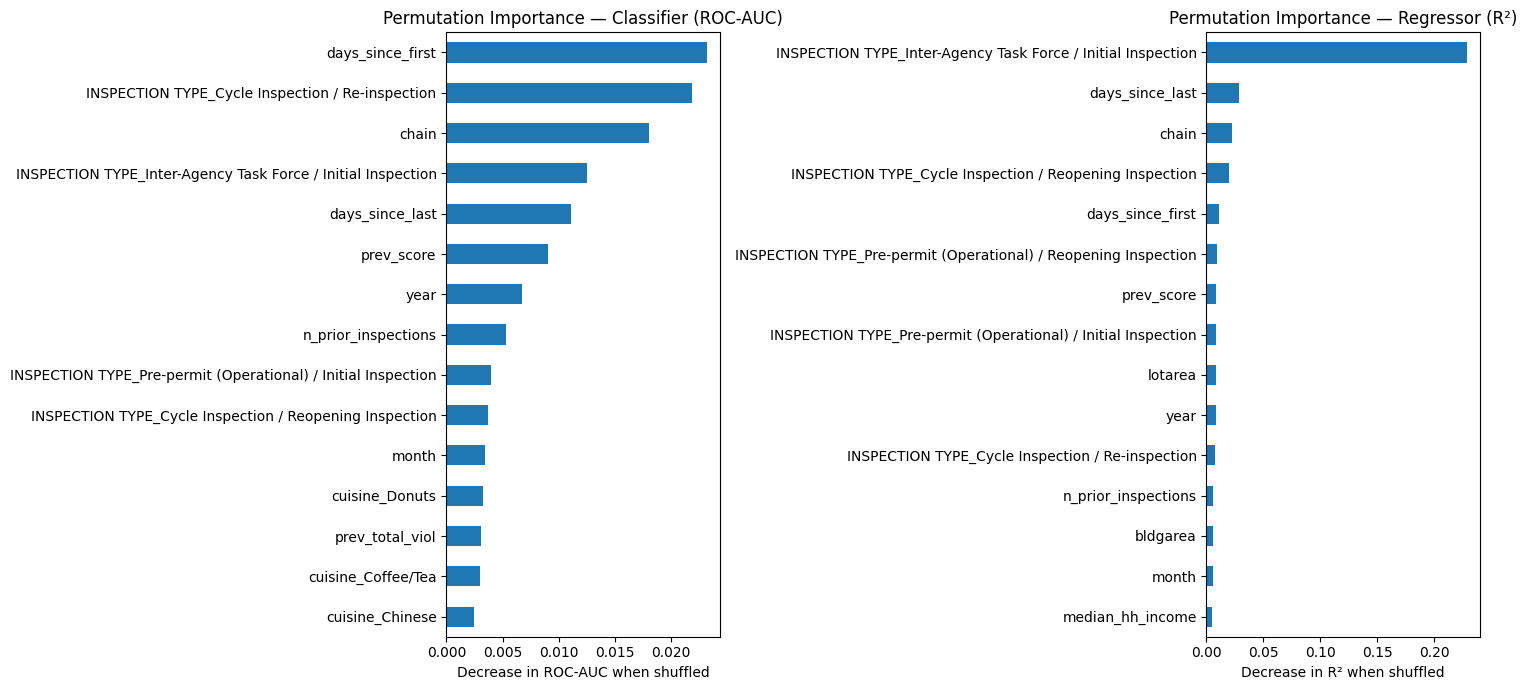

In [70]:
# Visualize permutation importance for both tuned models.
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# A larger decrease in ROC-AUC when shuffled indicates the feature is more useful for classification.
perm_class_importance.head(15).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Permutation Importance — Classifier (ROC-AUC)")
axes[0].set_xlabel("Decrease in ROC-AUC when shuffled")

# A larger decrease in test R-squared when shuffled indicates greater usefulness for regression.
perm_reg_importance.head(15).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Permutation Importance — Regressor (R²)")
axes[1].set_xlabel("Decrease in R² when shuffled")

# Adjust plot spacing and display.
plt.tight_layout()
plt.show()

#### Key Results Summary Table

In [71]:
# Combine all four Random Forest metric sets into a report-friendly table.
rf_metrics_report = pd.concat([
    pd.DataFrame([baseline_class_metrics], index=["RF classifier (baseline)"]),
    pd.DataFrame([tuned_class_metrics], index=["RF classifier (tuned)"]),
    pd.DataFrame([baseline_reg_metrics], index=["RF regressor (baseline)"]),
    pd.DataFrame([tuned_reg_metrics], index=["RF regressor (tuned)"])
], axis=0)

# Display the metrics table, then the top predictors for both model types.
display(rf_metrics_report.round(4))

print("Top 10 predictors — classification:")
display(class_importance.head(10).to_frame().round(4))

print("Top 10 predictors — regression:")
display(reg_importance.head(10).to_frame().round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,RMSE,MAE,R2
RF classifier (baseline),0.6407,0.5858,0.3838,0.4638,0.6733,NaN,NaN,NaN
RF classifier (tuned),0.6423,0.5617,0.5300,0.5454,0.6838,NaN,NaN,NaN
RF regressor (baseline),NaN,NaN,NaN,NaN,NaN,0.6842,0.5211,0.2677
RF regressor (tuned),NaN,NaN,NaN,NaN,NaN,0.6773,0.5199,0.2825


Top 10 predictors — classification:


,Classifier importance
lotarea,0.0862
bldgarea,0.0859
days_since_first,0.0785
median_hh_income,0.0726
bldg_age,0.0721
days_since_last,0.0684
population,0.0683
unitstotal,0.0607
month,0.0557
prev_score,0.0517


Top 10 predictors — regression:


,Regressor importance
INSPECTION TYPE_Inter-Agency Task Force / Initial Inspection,0.1937
days_since_last,0.0741
lotarea,0.0665
bldgarea,0.0659
median_hh_income,0.0534
bldg_age,0.0525
population,0.0498
days_since_first,0.0496
unitstotal,0.0449
prev_score,0.0430
